In [ ]:
%load_ext autoreload
%autoreload 2
from codit.model_module.diffusion_model import CoDiTModel, restore_checkpoint
from codit.data_module import config_paths

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Tranform diffusion model

In [ ]:
model_type = "GRU"
data_set = "coastline"
model_name = f"ddpm_{model_type}_{data_set}_conv_adam_constant"
if data_set == 'coastline':
    length = 24
if data_set == 'open_ocean':
    length = 72
context_encoder_type = "conv"
K = 100

params = {
    "prediction_length": length,
    "dt": 1.0 / length,
    "model_type": model_type,
    "context_encoder_type": context_encoder_type,
    "K": K,}

model = CoDiTModel(name=model_name, params=params)

params, loss_list, val_loss_list, std = restore_checkpoint(model.ckpt_dir + 'final')
model.nn_params = params
model.std = std

In [30]:
export_path = '/mydata/adopt/christian/CoDiT/data/trained_models/'
model.export_trained_model(f'codit_{model_type}_{data_set}', export_path=export_path)

Exception: Model codit_GRU_coastline already exists in /mydata/adopt/christian/CoDiT/data/trained_models/codit_GRU_coastline. Please delete it or change the model name.

In [23]:
export_path = '/mydata/adopt/christian/CoDiT/data/trained_models/'
model_name = f'codit_{model_type}_{data_set}'
loaded_model = DiffusionModel.import_trained_model(model_name, import_path=export_path)

# Transform CNN

In [31]:
from codit.model_module.conv_net import ConvNetModel

name = f'conv_net_{data_set}'
model = ConvNetModel(name=name, params={})


In [33]:
export_path = '/mydata/adopt/christian/CoDiT/data/trained_models/'
model.export_trained_model(f'cnn_{data_set}', export_path=export_path)

Exception: Model cnn_coastline already exists at /mydata/adopt/christian/CoDiT/data/trained_models/cnn_coastline. Please delete it or change the model name.

In [34]:
loaded_model = ConvNetModel.import_trained_model(f'cnn_{data_set}', import_path=export_path)

In [5]:
import os
from codit.data_module import config_funcs
from codit.data_module.dataset import OceanDataset
config_path = os.path.join(
    config_paths.CONFIG_PATH,
    "open_ocean",
)
length = 72
files = os.listdir(config_path)
dataset_files = [f for f in files if f.endswith(".yml")]
val_datasets = []
for dataset_name in dataset_files:
    config = config_funcs.load_config(dataset_name.split(".")[0], config_path)
    if config["start_date"].year >= 2020 and os.path.exists(config["dataset_path"]):
        val_datasets.append(dataset_name)
        
data_name = val_datasets[1].split(".")[0]
#data_name = 'open_ocean_patch_9_year_2020'
config = config_funcs.load_config(data_name, config_path)
test_dataset = OceanDataset(config, length, 16, 10000, "linear")

In [6]:
data_name

'open_ocean_patch_9_year_2020'

In [7]:
start_position, times, interpolator, coordinates = test_dataset[1]

In [8]:
pred_coord = loaded_model.predict(
    start_position,
    times,
    interpolator,
    test_dataset,
    num_samples=100,
)

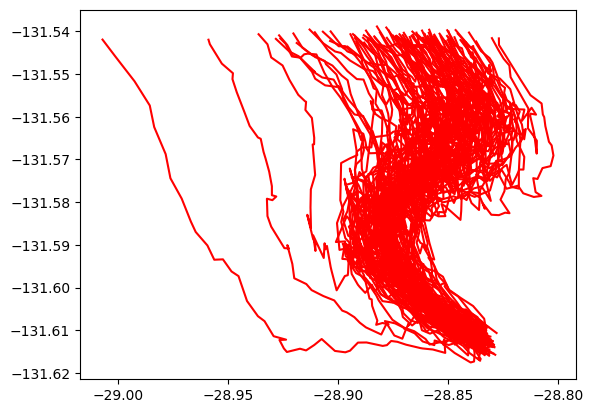

In [9]:
from matplotlib import pyplot as plt
plt.plot(pred_coord[:, :, 0].T, pred_coord[:, :, 1].T, 'r', label='Predicted Path')
plt.show()